## 0. Setup
Colab already ships `nltk`, `scikit-learn`, `networkx`, `pandas`, `matplotlib` and `ipywidgets`. The cell below downloads the NLTK resources and **falls back gracefully** (regex tokeniser, scikit-learn stopwords, rule-based lemmatiser) if a download is blocked, so the notebook never crashes on a network hiccup.

In [11]:
import re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
# pandas >=3 defaults to arrow-backed strings, which sklearn cannot index in
# cross_validate; force classic python-object strings.
pd.set_option("mode.string_storage", "python")
pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42

NLTK_RESOURCES = {
    "punkt": "tokenizers/punkt",
    "punkt_tab": "tokenizers/punkt_tab",
    "stopwords": "corpora/stopwords",
    "wordnet": "corpora/wordnet",
    "omw-1.4": "corpora/omw-1.4",
}
for pkg, path in NLTK_RESOURCES.items():
    try:
        nltk.data.find(path)
    except LookupError:
        try:
            nltk.download(pkg, quiet=True)
        except Exception as exc:
            print(f"[warn] could not download {pkg}: {exc}")

# ---- capability probes with fallbacks ----
try:
    from nltk.tokenize import word_tokenize
    word_tokenize("heart health check")
    TOKENIZER = "nltk.word_tokenize"
except Exception:
    word_tokenize = lambda text: re.findall(r"[a-z0-9]+(?:[-'][a-z0-9]+)*", text)
    TOKENIZER = "regex fallback"

try:
    from nltk.corpus import stopwords
    BASE_STOPWORDS = set(stopwords.words("english"))
    STOPWORD_SRC = "nltk"
except Exception:
    BASE_STOPWORDS = set(ENGLISH_STOP_WORDS)
    STOPWORD_SRC = "sklearn fallback"

try:
    from nltk.stem import WordNetLemmatizer
    _wnl = WordNetLemmatizer()
    _wnl.lemmatize("arteries")
    def lemmatize(tok):
        return _wnl.lemmatize(_wnl.lemmatize(tok, "n"), "v")
    LEMMATIZER = "WordNet (noun→verb)"
except Exception:
    def lemmatize(tok):
        for suf, rep in (("ies", "y"), ("sses", "ss"), ("ing", ""), ("ed", ""), ("s", "")):
            if tok.endswith(suf) and len(tok) - len(suf) >= 3:
                return tok[: -len(suf)] + rep
        return tok
    LEMMATIZER = "rule-based fallback"

print(f"Tokenizer : {TOKENIZER}\nStopwords : {STOPWORD_SRC} ({len(BASE_STOPWORDS)} words)\nLemmatizer: {LEMMATIZER}")

Tokenizer : nltk.word_tokenize
Stopwords : nltk (198 words)
Lemmatizer: WordNet (noun→verb)


## 1. Labelled Query Corpus
**168 queries across 7 intent categories** (24 per intent — balanced, so no class dominates the classifier). Queries deliberately vary phrasing, length and Indian context (ghee, samosa, gutka, millets, TMT, 2D echo) so the model learns intent rather than memorising templates.

| Intent | Covers |
|---|---|
| `symptoms` | Heart attack, angina, heart-failure and arrhythmia warning signs |
| `risk_factors` | Smoking, diabetes, obesity, family history, age, stress, alcohol |
| `diet_nutrition` | Heart-healthy foods, salt, oils, ghee, eggs, sugar |
| `exercise_lifestyle` | Physical activity, yoga, cardiac rehab, sleep, quitting smoking |
| `blood_pressure` | Normal ranges, hypertension, low BP, home monitoring |
| `cholesterol` | LDL/HDL, triglycerides, plaque, atherosclerosis |
| `tests_treatment` | ECG, echo, TMT, angiography, statins, stents, pacemakers |

In [12]:
CORPUS = {
    "symptoms": [
        "What are the symptoms of a heart attack?",
        "What are the early warning signs of heart disease?",
        "How do I know if my chest pain is related to my heart?",
        "Do women experience different heart attack symptoms than men?",
        "What does angina feel like?",
        "Can pain in the left arm be a sign of a heart problem?",
        "Is shortness of breath a symptom of heart failure?",
        "Why do my ankles swell, is it related to the heart?",
        "What are the signs of an irregular heartbeat?",
        "Can a heart attack happen without chest pain?",
        "What does a silent heart attack mean?",
        "Is jaw pain a warning sign of heart trouble?",
        "How does heart attack pain feel?",
        "What are the warning signs of a heart problem in older people?",
        "Can heart disease cause fatigue and tiredness?",
        "Is sweating with chest discomfort a heart symptom?",
        "Why do I feel breathless when climbing stairs?",
        "Can a heart problem cause nausea or indigestion?",
        "What are the symptoms of a blocked artery?",
        "Can palpitations be a sign of heart disease?",
        "Is dizziness or fainting a symptom of a heart condition?",
        "What are the signs of heart failure in elderly people?",
        "Does pain in the back or shoulder indicate a heart problem?",
        "What symptoms do diabetics get during a heart attack?",
    ],
    "risk_factors": [
        "What are the main risk factors for heart disease?",
        "Does smoking increase the risk of heart attack?",
        "Can diabetes damage my heart?",
        "Is heart disease hereditary if it runs in my family?",
        "Does being overweight affect heart health?",
        "How does stress affect the heart?",
        "At what age does the risk of heart disease increase?",
        "Does drinking alcohol harm the heart?",
        "Are men more at risk of heart disease than women?",
        "Can lack of sleep raise my chances of heart problems?",
        "Does air pollution affect cardiovascular risk?",
        "Which habits put me at risk of a heart attack?",
        "Who is most likely to get heart disease?",
        "Do Indians have a higher risk of heart disease?",
        "Does chewing tobacco or gutka affect the heart?",
        "Is high cholesterol a risk factor for heart attack?",
        "Can a sedentary lifestyle increase heart disease risk?",
        "Does menopause increase heart disease risk in women?",
        "Is my risk higher if my father had a heart attack?",
        "Do energy drinks increase the risk of heart problems?",
        "Can obesity in children lead to heart disease later?",
        "Does vaping damage the heart?",
        "Can high blood pressure increase my heart risk?",
        "What increases the chance of having a second heart attack?",
    ],
    "diet_nutrition": [
        "What foods are good for heart health?",
        "Which foods should I avoid to protect my heart?",
        "Is the Mediterranean diet good for the heart?",
        "How much salt should I eat per day for a healthy heart?",
        "Are eggs bad for my heart?",
        "Is ghee or butter harmful for the heart?",
        "Which cooking oil is best for heart health?",
        "Do omega-3 fatty acids from fish help the heart?",
        "Is coffee safe for people with heart disease?",
        "What should a heart patient eat for breakfast?",
        "Are nuts and seeds beneficial for the heart?",
        "How does sugar intake affect heart health?",
        "Which fruits are good for the heart?",
        "Is a vegetarian diet better for heart health?",
        "Should I eat less red meat for my heart?",
        "Are fried foods like samosa and pakora bad for the heart?",
        "Is dark chocolate good for the heart?",
        "How much fibre should I eat for a healthy heart?",
        "Are processed foods and pickles harmful for heart patients?",
        "What is the DASH diet?",
        "Are millets and whole grains good for the heart?",
        "Which vegetables protect against heart disease?",
        "What should I eat to keep my heart healthy?",
        "What is a healthy diet plan for heart patients?",
    ],
    "exercise_lifestyle": [
        "How much exercise do I need for a healthy heart?",
        "What is the best exercise for heart health?",
        "Is walking daily good for my heart?",
        "Can I lift weights if I have heart disease?",
        "Does yoga help improve heart health?",
        "How can I start exercising safely after a heart attack?",
        "What is cardiac rehabilitation?",
        "How can I quit smoking to protect my heart?",
        "Does sitting for long hours harm my heart?",
        "How does good sleep help the heart?",
        "What lifestyle changes can prevent heart disease?",
        "How can I manage stress to keep my heart healthy?",
        "How many steps a day are good for the heart?",
        "Is running or jogging good for heart health?",
        "Is swimming a good workout for the heart?",
        "What type of physical activity strengthens the heart?",
        "Is it safe to go to the gym with high blood pressure?",
        "How many minutes of exercise per week does my heart need?",
        "Does meditation reduce the risk of heart disease?",
        "How can I lose weight to improve my heart health?",
        "Can I play sports after angioplasty?",
        "What are heart-healthy daily habits?",
        "How long should I walk every day for fitness?",
        "Does cycling improve cardiovascular fitness?",
    ],
    "blood_pressure": [
        "What is a normal blood pressure reading?",
        "What causes high blood pressure?",
        "How can I lower my blood pressure naturally?",
        "What are the symptoms of hypertension?",
        "Is low blood pressure dangerous?",
        "How often should I check my blood pressure at home?",
        "What do the systolic and diastolic numbers mean?",
        "Can high blood pressure cause a stroke or heart attack?",
        "Why is hypertension called a silent killer?",
        "How does salt raise blood pressure?",
        "Which home BP monitor reading is considered high?",
        "Can blood pressure be high in young people?",
        "What is the ideal blood pressure for adults?",
        "Is 140 over 90 high blood pressure?",
        "What foods help reduce high blood pressure?",
        "Can stress raise my blood pressure?",
        "Why does my blood pressure go up in the morning?",
        "How do I measure blood pressure correctly?",
        "Is a blood pressure of 90 over 60 too low?",
        "What is a hypertensive crisis?",
        "Can high blood pressure be cured permanently?",
        "Does coffee increase blood pressure?",
        "What lifestyle changes control hypertension?",
        "What is white coat hypertension?",
    ],
    "cholesterol": [
        "What is a normal cholesterol level?",
        "What is the difference between LDL and HDL cholesterol?",
        "How can I reduce my LDL cholesterol?",
        "What are triglycerides and why do they matter?",
        "Does high cholesterol cause heart disease?",
        "What foods raise good HDL cholesterol?",
        "How often should I get my cholesterol checked?",
        "Can thin people have high cholesterol?",
        "How does plaque build up in the arteries?",
        "What is atherosclerosis?",
        "Is high cholesterol genetic?",
        "What do my lipid profile numbers mean?",
        "What causes high cholesterol?",
        "Which foods lower cholesterol?",
        "Is eating oats good for lowering cholesterol?",
        "What is a good HDL level?",
        "Can exercise raise HDL and lower LDL?",
        "What are high triglycerides and how do I lower them?",
        "Is cholesterol in food the same as blood cholesterol?",
        "At what LDL level do I need treatment?",
        "What is familial hypercholesterolemia?",
        "How does cholesterol block arteries?",
        "Does ghee raise cholesterol levels?",
        "What is total cholesterol?",
    ],
    "tests_treatment": [
        "What tests are used to diagnose heart disease?",
        "What is an ECG and why is it done?",
        "What does an echocardiogram show?",
        "What is a treadmill stress test?",
        "What is angiography and when is it needed?",
        "What is the difference between angioplasty and bypass surgery?",
        "What are statins used for?",
        "Why do doctors prescribe aspirin for heart patients?",
        "What is a stent?",
        "What are the side effects of beta blockers?",
        "What is a pacemaker and who needs one?",
        "What is a coronary calcium score?",
        "What is a Holter monitor test?",
        "How is a heart attack diagnosed in hospital?",
        "What does a troponin blood test show?",
        "When is bypass surgery recommended?",
        "How long does a stent last?",
        "What are ACE inhibitors used for?",
        "What does a 2D echo test check?",
        "How is heart failure treated?",
        "What medicines are given after a heart attack?",
        "What is a CT coronary angiogram?",
        "Is angioplasty a major surgery?",
        "Do I need a TMT test if my ECG is normal?",
    ],
}

INTENT_LABELS = {
    "symptoms": "Symptoms & Warning Signs",
    "risk_factors": "Risk Factors",
    "diet_nutrition": "Diet & Nutrition",
    "exercise_lifestyle": "Exercise & Lifestyle",
    "blood_pressure": "Blood Pressure",
    "cholesterol": "Cholesterol",
    "tests_treatment": "Tests & Treatment",
}

corpus_df = pd.DataFrame([(q, intent) for intent, qs in CORPUS.items() for q in qs],
                         columns=["query", "intent"])
corpus_df.to_csv("heart_health_corpus.csv", index=False)

print(f"Total queries: {len(corpus_df)} | Intents: {corpus_df.intent.nunique()}")
display(corpus_df.intent.value_counts().rename("count").to_frame())
display(corpus_df.groupby("intent").head(3).reset_index(drop=True))

Total queries: 168 | Intents: 7


,count
intent,
symptoms,24
risk_factors,24
diet_nutrition,24
exercise_lifestyle,24
blood_pressure,24
cholesterol,24
tests_treatment,24


,query,intent
0,What are the symptoms of a heart attack?,symptoms
1,What are the early warning signs of heart disease?,symptoms
2,How do I know if my chest pain is related to my heart?,symptoms
3,What are the main risk factors for heart disease?,risk_factors
4,Does smoking increase the risk of heart attack?,risk_factors
5,Can diabetes damage my heart?,risk_factors
6,What foods are good for heart health?,diet_nutrition
7,Which foods should I avoid to protect my heart?,diet_nutrition
8,Is the Mediterranean diet good for the heart?,diet_nutrition
9,How much exercise do I need for a healthy heart?,exercise_lifestyle


## 2. Hierarchical Taxonomy
**5 major categories, 15 subcategories**, each with leaf topics. Every intent is anchored to a taxonomy path, so the assistant can tell the user *where* their question sits in the domain.

In [13]:
TAXONOMY = {
    "Heart Health": {
        "Cardiovascular Conditions": {
            "Coronary Artery Disease & Heart Attack": ["atherosclerosis", "myocardial infarction", "angina"],
            "Hypertension": ["primary hypertension", "hypertensive crisis", "hypotension"],
            "Heart Failure": ["fluid retention", "reduced pumping"],
            "Arrhythmia": ["atrial fibrillation", "palpitations", "bradycardia"],
        },
        "Symptoms & Warning Signs": {
            "Chest Pain / Angina": ["pressure", "radiating arm/jaw pain"],
            "Breathlessness & Swelling": ["dyspnoea", "ankle oedema"],
            "Palpitations & Dizziness": ["racing heart", "fainting"],
        },
        "Risk Factors": {
            "Modifiable": ["smoking", "obesity", "diabetes", "high LDL", "inactivity", "stress", "alcohol"],
            "Non-Modifiable": ["age", "sex", "family history", "ethnicity"],
        },
        "Prevention & Lifestyle": {
            "Diet & Nutrition": ["salt", "fats & oils", "fibre", "sugar"],
            "Physical Activity": ["aerobic", "strength", "cardiac rehab"],
            "Sleep, Stress & Smoking Cessation": ["sleep hygiene", "yoga", "quitting tobacco"],
        },
        "Diagnosis & Treatment": {
            "Diagnostic Tests": ["ECG", "echocardiogram", "TMT", "angiography", "lipid profile"],
            "Medications": ["statins", "aspirin", "beta-blockers", "ACE inhibitors"],
            "Procedures": ["angioplasty & stent", "bypass (CABG)", "pacemaker"],
        },
    }
}

INTENT_TAXONOMY = {
    "symptoms": "Symptoms & Warning Signs",
    "risk_factors": "Risk Factors › Modifiable / Non-Modifiable",
    "diet_nutrition": "Prevention & Lifestyle › Diet & Nutrition",
    "exercise_lifestyle": "Prevention & Lifestyle › Physical Activity / Sleep, Stress & Smoking Cessation",
    "blood_pressure": "Cardiovascular Conditions › Hypertension",
    "cholesterol": "Cardiovascular Conditions › Coronary Artery Disease & Heart Attack (lipids)",
    "tests_treatment": "Diagnosis & Treatment › Diagnostic Tests / Medications / Procedures",
}

def print_tree(node, prefix=""):
    items = list(node.items()) if isinstance(node, dict) else [(leaf, None) for leaf in node]
    for i, (key, child) in enumerate(items):
        last = i == len(items) - 1
        print(prefix + ("└── " if last else "├── ") + key)
        if child:
            print_tree(child, prefix + ("    " if last else "│   "))

root = TAXONOMY["Heart Health"]
print("Heart Health")
print_tree(root)

n_major = len(root)
n_sub = sum(len(v) for v in root.values())
print(f"\nMajor categories: {n_major} | Subcategories: {n_sub} | "
      f"Min subcategories per category: {min(len(v) for v in root.values())}")
display(pd.DataFrame(INTENT_TAXONOMY.items(), columns=["intent", "taxonomy path"]))

Heart Health
├── Cardiovascular Conditions
│   ├── Coronary Artery Disease & Heart Attack
│   │   ├── atherosclerosis
│   │   ├── myocardial infarction
│   │   └── angina
│   ├── Hypertension
│   │   ├── primary hypertension
│   │   ├── hypertensive crisis
│   │   └── hypotension
│   ├── Heart Failure
│   │   ├── fluid retention
│   │   └── reduced pumping
│   └── Arrhythmia
│       ├── atrial fibrillation
│       ├── palpitations
│       └── bradycardia
├── Symptoms & Warning Signs
│   ├── Chest Pain / Angina
│   │   ├── pressure
│   │   └── radiating arm/jaw pain
│   ├── Breathlessness & Swelling
│   │   ├── dyspnoea
│   │   └── ankle oedema
│   └── Palpitations & Dizziness
│       ├── racing heart
│       └── fainting
├── Risk Factors
│   ├── Modifiable
│   │   ├── smoking
│   │   ├── obesity
│   │   ├── diabetes
│   │   ├── high LDL
│   │   ├── inactivity
│   │   ├── stress
│   │   └── alcohol
│   └── Non-Modifiable
│       ├── age
│       ├── sex
│       ├── family history
│      

,intent,taxonomy path
0,symptoms,Symptoms & Warning Signs
1,risk_factors,Risk Factors › Modifiable / Non-Modifiable
2,diet_nutrition,Prevention & Lifestyle › Diet & Nutrition
3,exercise_lifestyle,"Prevention & Lifestyle › Physical Activity / Sleep, Stress & Smoking Cessation"
4,blood_pressure,Cardiovascular Conditions › Hypertension
5,cholesterol,Cardiovascular Conditions › Coronary Artery Disease & Heart Attack (lipids)
6,tests_treatment,Diagnosis & Treatment › Diagnostic Tests / Medications / Procedures


## 3. Domain Concepts & Relationships (Knowledge Graph)
**17 typed concepts and 18 semantic relationships** stored as `(subject, relation, object)` triples. Each concept has surface-form aliases so it can be **detected inside user queries**; the assistant then surfaces the matching graph facts in its answer (concept-level reasoning, not just keyword lookup).

Concepts: 17 | Relationships: 18


,subject,relation,object
0,Smoking,increases_risk_of,Coronary Artery Disease
1,Diabetes,increases_risk_of,Coronary Artery Disease
2,Obesity,contributes_to,Hypertension
3,Obesity,contributes_to,Diabetes
4,Stress,contributes_to,Hypertension
5,Excess Salt,raises,Hypertension
6,Hypertension,increases_risk_of,Heart Attack
7,Hypertension,increases_risk_of,Stroke
8,High LDL Cholesterol,causes,Atherosclerosis
9,Atherosclerosis,leads_to,Coronary Artery Disease


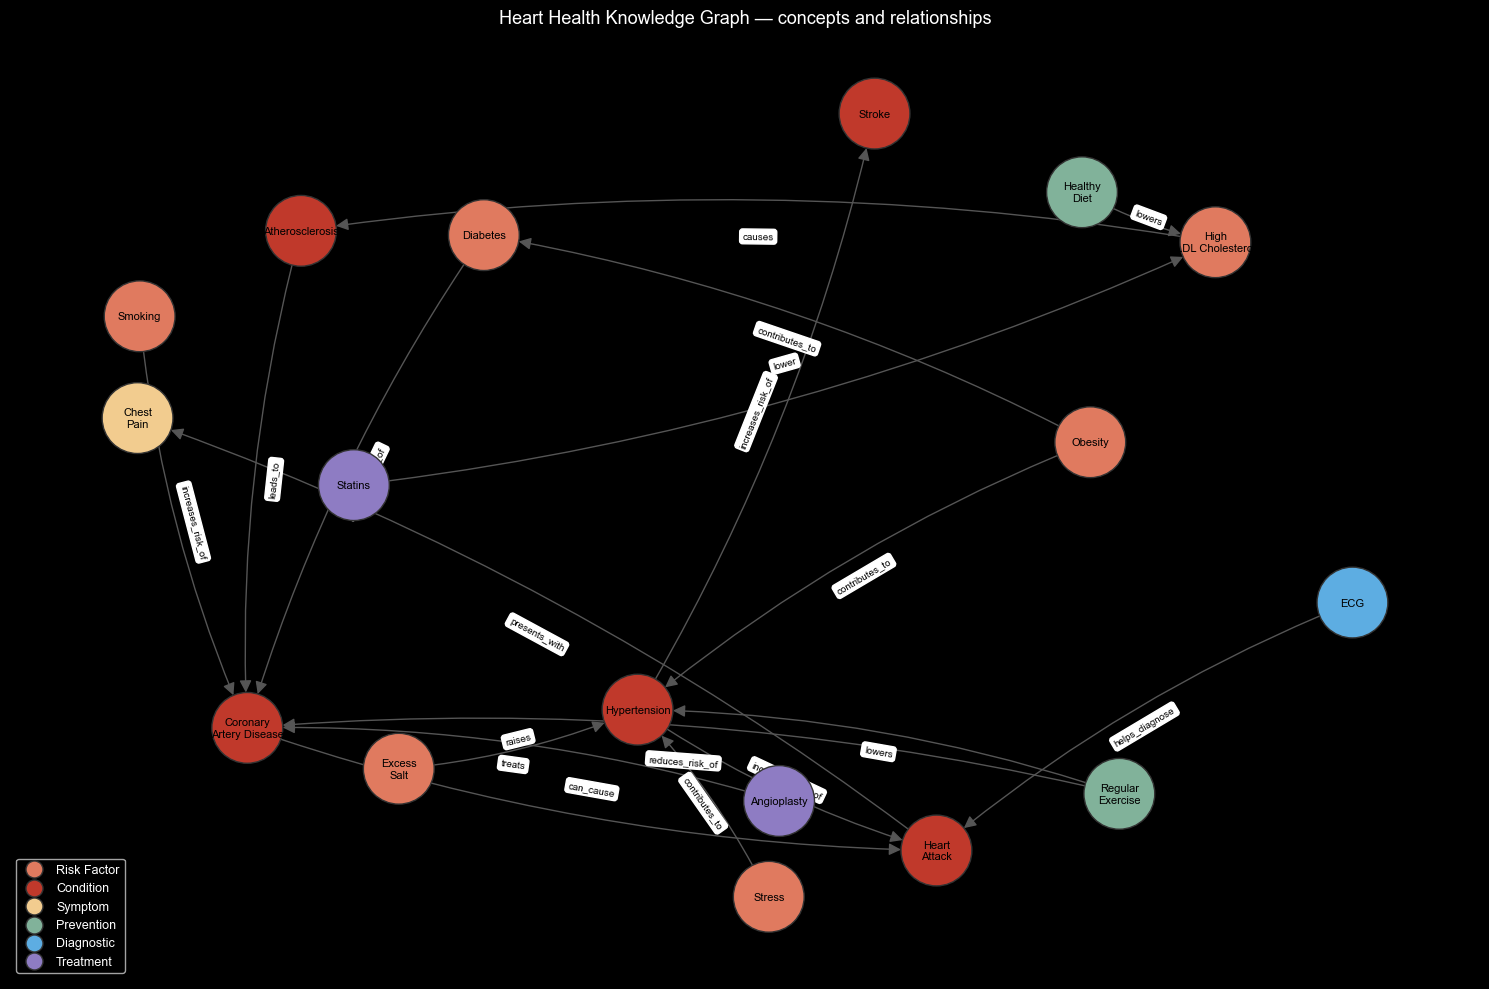

In [14]:
CONCEPTS = {
    # concept                : (type,          aliases detected in queries)
    "Smoking":                 ("Risk Factor",  ["smoking", "smoke", "cigarette", "tobacco", "bidi"]),
    "Diabetes":                ("Risk Factor",  ["diabetes", "diabetic", "blood sugar"]),
    "Obesity":                 ("Risk Factor",  ["obesity", "obese", "overweight", "belly fat"]),
    "Stress":                  ("Risk Factor",  ["stress", "anxiety", "tension"]),
    "Excess Salt":             ("Risk Factor",  ["salt", "sodium"]),
    "High LDL Cholesterol":    ("Risk Factor",  ["cholesterol", "ldl", "lipid"]),
    "Hypertension":            ("Condition",    ["hypertension", "high blood pressure", "blood pressure", "bp"]),
    "Atherosclerosis":         ("Condition",    ["atherosclerosis", "plaque", "blocked artery", "artery"]),
    "Coronary Artery Disease": ("Condition",    ["coronary", "heart disease", "cad", "blockage"]),
    "Heart Attack":            ("Condition",    ["heart attack", "myocardial infarction"]),
    "Stroke":                  ("Condition",    ["stroke"]),
    "Chest Pain":              ("Symptom",      ["chest pain", "angina", "chest pressure", "chest tightness"]),
    "Regular Exercise":        ("Prevention",   ["exercise", "walking", "yoga", "physical activity"]),
    "Healthy Diet":            ("Prevention",   ["diet", "food", "fruit", "vegetable", "oil"]),
    "ECG":                     ("Diagnostic",   ["ecg", "ekg", "electrocardiogram"]),
    "Statins":                 ("Treatment",    ["statin", "atorvastatin", "rosuvastatin"]),
    "Angioplasty":             ("Treatment",    ["angioplasty", "stent"]),
}

RELATIONSHIPS = [
    ("Smoking", "increases_risk_of", "Coronary Artery Disease"),
    ("Diabetes", "increases_risk_of", "Coronary Artery Disease"),
    ("Obesity", "contributes_to", "Hypertension"),
    ("Obesity", "contributes_to", "Diabetes"),
    ("Stress", "contributes_to", "Hypertension"),
    ("Excess Salt", "raises", "Hypertension"),
    ("Hypertension", "increases_risk_of", "Heart Attack"),
    ("Hypertension", "increases_risk_of", "Stroke"),
    ("High LDL Cholesterol", "causes", "Atherosclerosis"),
    ("Atherosclerosis", "leads_to", "Coronary Artery Disease"),
    ("Coronary Artery Disease", "can_cause", "Heart Attack"),
    ("Heart Attack", "presents_with", "Chest Pain"),
    ("Regular Exercise", "lowers", "Hypertension"),
    ("Regular Exercise", "reduces_risk_of", "Coronary Artery Disease"),
    ("Healthy Diet", "lowers", "High LDL Cholesterol"),
    ("Statins", "lower", "High LDL Cholesterol"),
    ("ECG", "helps_diagnose", "Heart Attack"),
    ("Angioplasty", "treats", "Coronary Artery Disease"),
]

assert len(CONCEPTS) >= 8 and len(RELATIONSHIPS) >= 10
assert all(s in CONCEPTS and o in CONCEPTS for s, _, o in RELATIONSHIPS), "relationship references unknown concept"

KG = nx.DiGraph()
for c, (ctype, _) in CONCEPTS.items():
    KG.add_node(c, type=ctype)
for s, r, o in RELATIONSHIPS:
    KG.add_edge(s, o, relation=r)

print(f"Concepts: {KG.number_of_nodes()} | Relationships: {KG.number_of_edges()}")
display(pd.DataFrame(RELATIONSHIPS, columns=["subject", "relation", "object"]))

TYPE_COLOURS = {"Risk Factor": "#E07A5F", "Condition": "#C0392B", "Symptom": "#F2CC8F",
                "Prevention": "#81B29A", "Diagnostic": "#5DADE2", "Treatment": "#8E7CC3"}
plt.figure(figsize=(15, 10))
pos = nx.spring_layout(KG, seed=7, k=1.6)
nx.draw_networkx_nodes(KG, pos, node_size=2600,
                       node_color=[TYPE_COLOURS[KG.nodes[n]["type"]] for n in KG.nodes], edgecolors="#333")
nx.draw_networkx_labels(KG, pos, labels={n: n.replace(" ", "\n", 1) for n in KG.nodes}, font_size=8)
nx.draw_networkx_edges(KG, pos, arrows=True, arrowsize=18, edge_color="#555", node_size=2600,
                       connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(KG, pos, edge_labels=nx.get_edge_attributes(KG, "relation"), font_size=7)
for t, col in TYPE_COLOURS.items():
    plt.scatter([], [], c=col, s=150, label=t, edgecolors="#333")
plt.legend(loc="lower left", fontsize=9, frameon=True)
plt.title("Heart Health Knowledge Graph — concepts and relationships", fontsize=13)
plt.axis("off"); plt.tight_layout(); plt.show()

In [15]:
def detect_concepts(text):
    # Concepts whose aliases appear in the text (whole-word / phrase match).
    t = text.lower()
    found = []
    for concept, (_, aliases) in CONCEPTS.items():
        if any(re.search(rf"\b{re.escape(a)}\b", t) for a in aliases):
            found.append(concept)
    return found

def kg_facts(concepts, limit=3):
    # One-hop facts touching any detected concept, rendered as readable sentences.
    facts = []
    for s, r, o in RELATIONSHIPS:
        if s in concepts or o in concepts:
            facts.append(f"{s} {r.replace('_', ' ')} {o}")
    return facts[:limit]

def kg_path(source, target):
    # Multi-hop reasoning chain through the graph, e.g. Obesity → Hypertension → Heart Attack.
    try:
        path = nx.shortest_path(KG, source, target)
    except (nx.NetworkXNoPath, nx.NodeNotFound):
        return None
    hops = [f"{a} —{KG.edges[a, b]['relation']}→ {b}" for a, b in zip(path, path[1:])]
    return "  |  ".join(hops)

q = "Does smoking or high cholesterol lead to a heart attack?"
print("Query           :", q)
print("Detected        :", detect_concepts(q))
print("Facts           :", kg_facts(detect_concepts(q), limit=5))
print("Reasoning chain :", kg_path("High LDL Cholesterol", "Chest Pain"))
print("Reasoning chain :", kg_path("Obesity", "Stroke"))

Query           : Does smoking or high cholesterol lead to a heart attack?
Detected        : ['Smoking', 'High LDL Cholesterol', 'Heart Attack']
Facts           : ['Smoking increases risk of Coronary Artery Disease', 'Hypertension increases risk of Heart Attack', 'High LDL Cholesterol causes Atherosclerosis', 'Coronary Artery Disease can cause Heart Attack', 'Heart Attack presents with Chest Pain']
Reasoning chain : High LDL Cholesterol —causes→ Atherosclerosis  |  Atherosclerosis —leads_to→ Coronary Artery Disease  |  Coronary Artery Disease —can_cause→ Heart Attack  |  Heart Attack —presents_with→ Chest Pain
Reasoning chain : Obesity —contributes_to→ Hypertension  |  Hypertension —increases_risk_of→ Stroke


## 4. NLP Preprocessing
Pipeline: **lowercase → concept/synonym normalisation → tokenisation → punctuation & stopword removal → lemmatisation**.

*Design notes*
- Negations and temporal words (`not`, `no`, `after`, `before`, `during`) are **kept** — "after a heart attack" and "before a heart attack" mean different things.
- A small synonym map normalises colloquial / Indian-English variants onto canonical domain terms (`bp → blood pressure`, `ticker → heart`, `tablets → medication`). This is what lets the classifier generalise to differently-worded queries it never saw in training.

In [16]:
KEEP_WORDS = {"no", "not", "nor", "after", "before", "during", "against", "high", "low"}
STOPWORDS = BASE_STOPWORDS - KEEP_WORDS

SYNONYMS = [
    (r"\bb\.?p\.?\b", "blood pressure"),
    (r"\bticker\b", "heart"),
    (r"\bcardiac\b", "heart"),
    (r"\b(eatables|meals?|dishes|food items)\b", "food"),
    (r"\b(workouts?|gym|jogging|cardio)\b", "exercise"),
    (r"\b(tablets?|pills?|medicines?|drugs?)\b", "medication"),
    (r"\b(cigarettes?|bidis?|tobacco|fags?)\b", "smoking"),
    (r"\bobese\b", "overweight"),
    (r"\bblood sugar\b", "diabetes"),
    (r"\bekg\b", "ecg"),
    (r"\bbad cholesterol\b", "ldl cholesterol"),
    (r"\bgood cholesterol\b", "hdl cholesterol"),
]

def normalise(text):
    t = text.lower().replace("’", "'")
    for pat, rep in SYNONYMS:
        t = re.sub(pat, rep, t)
    return t

def preprocess(text, verbose=False):
    if not isinstance(text, str):
        text = "" if text is None else str(text)
    lowered = text.lower()
    normalised = normalise(lowered)
    tokens = word_tokenize(normalised)
    tokens = [t for t in tokens if t not in string.punctuation and re.search(r"[a-z0-9]", t)]
    content = [t for t in tokens if t not in STOPWORDS]
    lemmas = [lemmatize(t) for t in content]
    if verbose:
        return {"1. original": text, "2. lowercase": lowered, "3. normalised": normalised,
                "4. tokens": tokens, "5. no stopwords": content, "6. lemmas": lemmas}
    return " ".join(lemmas)

for sample in ["What are the symptoms of a heart attack?",
               "How can I bring my BP down without tablets?",
               "Is walking daily good for my heart after angioplasty?"]:
    steps = preprocess(sample, verbose=True)
    display(pd.DataFrame({"step": steps.keys(), "output": [str(v) for v in steps.values()]}))

corpus_df["clean"] = corpus_df["query"].apply(preprocess)
display(corpus_df[["query", "clean", "intent"]].head(8))

,step,output
0,1. original,What are the symptoms of a heart attack?
1,2. lowercase,what are the symptoms of a heart attack?
2,3. normalised,what are the symptoms of a heart attack?
3,4. tokens,"['what', 'are', 'the', 'symptoms', 'of', 'a', 'heart', 'attack']"
4,5. no stopwords,"['symptoms', 'heart', 'attack']"
5,6. lemmas,"['symptom', 'heart', 'attack']"


,step,output
0,1. original,How can I bring my BP down without tablets?
1,2. lowercase,how can i bring my bp down without tablets?
2,3. normalised,how can i bring my blood pressure down without medication?
3,4. tokens,"['how', 'can', 'i', 'bring', 'my', 'blood', 'pressure', 'down', 'without', 'medication']"
4,5. no stopwords,"['bring', 'blood', 'pressure', 'without', 'medication']"
5,6. lemmas,"['bring', 'blood', 'pressure', 'without', 'medication']"


,step,output
0,1. original,Is walking daily good for my heart after angioplasty?
1,2. lowercase,is walking daily good for my heart after angioplasty?
2,3. normalised,is walking daily good for my heart after angioplasty?
3,4. tokens,"['is', 'walking', 'daily', 'good', 'for', 'my', 'heart', 'after', 'angioplasty']"
4,5. no stopwords,"['walking', 'daily', 'good', 'heart', 'after', 'angioplasty']"
5,6. lemmas,"['walk', 'daily', 'good', 'heart', 'after', 'angioplasty']"


,query,clean,intent
0,What are the symptoms of a heart attack?,symptom heart attack,symptoms
1,What are the early warning signs of heart disease?,early warn sign heart disease,symptoms
2,How do I know if my chest pain is related to my heart?,know chest pain relate heart,symptoms
3,Do women experience different heart attack symptoms than men?,woman experience different heart attack symptom men,symptoms
4,What does angina feel like?,angina feel like,symptoms
5,Can pain in the left arm be a sign of a heart problem?,pain leave arm sign heart problem,symptoms
6,Is shortness of breath a symptom of heart failure?,shortness breath symptom heart failure,symptoms
7,"Why do my ankles swell, is it related to the heart?",ankle swell relate heart,symptoms


## 5. TF-IDF Feature Extraction & Intent Classification
Features are a **union of two TF-IDF views**:
- **word TF-IDF** (unigrams + bigrams) — captures terms and short phrases (`blood pressure`, `heart attack`);
- **character TF-IDF** (`char_wb`, 2–5-grams) — captures sub-word overlap, so `exercising`/`exercise`, `cardiologist`/`cardiac` or minor typos still share features. On a small corpus this is the single biggest generalisation gain.

`sublinear_tf=True` dampens repeated terms. Naive Bayes, Logistic Regression and Linear SVM are compared with **5-fold stratified cross-validation repeated 3×** (both with and without the character view), then the chosen model is evaluated on a **held-out stratified 25 % test split**.

**Deployed model: Logistic Regression** — it gives well-behaved class probabilities, which the low-confidence rule (R6) needs. LinearSVC has no `predict_proba`, and Naive Bayes probabilities are notoriously over-confident on short texts.

In [17]:
def make_tfidf(with_char=True):
    word = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
    if not with_char:
        return word
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)
    return FeatureUnion([("word", word), ("char", char)])

CANDIDATES = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(C=10, max_iter=5000, random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(C=1.0, random_state=RANDOM_STATE),
}

X_all, y_all = corpus_df["clean"].values, corpus_df["intent"].values
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for features, with_char in [("word", False), ("word + char", True)]:
  for name, clf in CANDIDATES.items():
    pipe = Pipeline([("features", make_tfidf(with_char)), ("clf", clf)])
    s = cross_validate(pipe, X_all, y_all, cv=cv,
                       scoring=["accuracy", "precision_macro", "recall_macro", "f1_macro"])
    rows.append({"features": features, "model": name,
                 "CV accuracy": s["test_accuracy"].mean(),
                 "CV precision (macro)": s["test_precision_macro"].mean(),
                 "CV recall (macro)": s["test_recall_macro"].mean(),
                 "CV F1 (macro)": s["test_f1_macro"].mean(),
                 "F1 std": s["test_f1_macro"].std()})
cv_results = pd.DataFrame(rows).set_index(["features", "model"]).round(3)
display(cv_results)

CV accuracy  CV precision (macro)  \
features    model                                                        
word        Multinomial Naive Bayes        0.731                 0.772   
            Logistic Regression            0.767                 0.787   
            Linear SVM                     0.765                 0.784   
word + char Multinomial Naive Bayes        0.789                 0.814   
            Logistic Regression            0.801                 0.821   
            Linear SVM                     0.801                 0.820   

                                     CV recall (macro)  CV F1 (macro)  F1 std  
features    model                                                              
word        Multinomial Naive Bayes              0.734          0.727   0.089  
            Logistic Regression                  0.770          0.762   0.074  
            Linear SVM                           0.769          0.759   0.076  
word + char Multinomial Naive Bayes              0.793          0.782   0.101  
            Logistic Regression                  0.805          0.795   0.077  
            Linear SVM                           0.805          0.795   0.074

In [18]:
X_train, X_test, y_train, y_test, q_train, q_test = train_test_split(
    X_all, y_all, corpus_df["query"].values, test_size=0.25, stratify=y_all, random_state=RANDOM_STATE)

def make_model():
    return Pipeline([("features", make_tfidf(with_char=True)),
                     ("clf", LogisticRegression(C=10, max_iter=5000, random_state=RANDOM_STATE))])

model = make_model().fit(X_train, y_train)

def word_vocab(m):
    return dict(m.named_steps["features"].transformer_list)["word"].vocabulary_

n_feat = model.named_steps["features"].transform(X_train[:1]).shape[1]
print(f"Train: {len(X_train)} | Test: {len(X_test)} | word vocabulary: {len(word_vocab(model))} | "
      f"total TF-IDF features (word + char): {n_feat}")

# Most discriminative word-level TF-IDF features per intent (LR coefficients)
clf = model.named_steps["clf"]
feat = np.array(model.named_steps["features"].get_feature_names_out())
is_word = np.char.startswith(feat.astype(str), "word__")
top = {}
for i, c in enumerate(clf.classes_):
    idx = [j for j in np.argsort(clf.coef_[i])[::-1] if is_word[j]][:6]
    top[c] = ", ".join(f.replace("word__", "") for f in feat[idx])
display(pd.DataFrame(top.items(), columns=["intent", "top TF-IDF features"]))

Train: 126 | Test: 42 | word vocabulary: 574 | total TF-IDF features (word + char): 3657


,intent,top TF-IDF features
0,blood_pressure,"pressure, blood pressure, blood, hypertension, symptom hypertension, control"
1,cholesterol,"cholesterol, triglyceride, ldl, level, build, build artery"
2,diet_nutrition,"diet, good heart, eat, heart, bad, bad heart"
3,exercise_lifestyle,"exercise, improve, daily, heart rehabilitation, rehabilitation, improve heart"
4,risk_factors,"risk, affect, increase, affect heart, increase heart, heart"
5,symptoms,"sign heart, sign, feel, pain, symptom, chest"
6,tests_treatment,"test, use, need, coronary, bypass surgery, bypass"


## 6. Model Evaluation
Accuracy, per-class precision / recall / F1, macro & weighted averages, and the confusion matrix on the held-out test set.

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
0,0.762,0.818,0.762,0.765,0.818,0.762,0.765


                    precision    recall  f1-score   support

    blood_pressure       1.00      0.83      0.91         6
       cholesterol       1.00      0.50      0.67         6
    diet_nutrition       0.71      0.83      0.77         6
exercise_lifestyle       0.67      0.67      0.67         6
      risk_factors       1.00      0.83      0.91         6
          symptoms       0.55      1.00      0.71         6
   tests_treatment       0.80      0.67      0.73         6

          accuracy                           0.76        42
         macro avg       0.82      0.76      0.76        42
      weighted avg       0.82      0.76      0.76        42



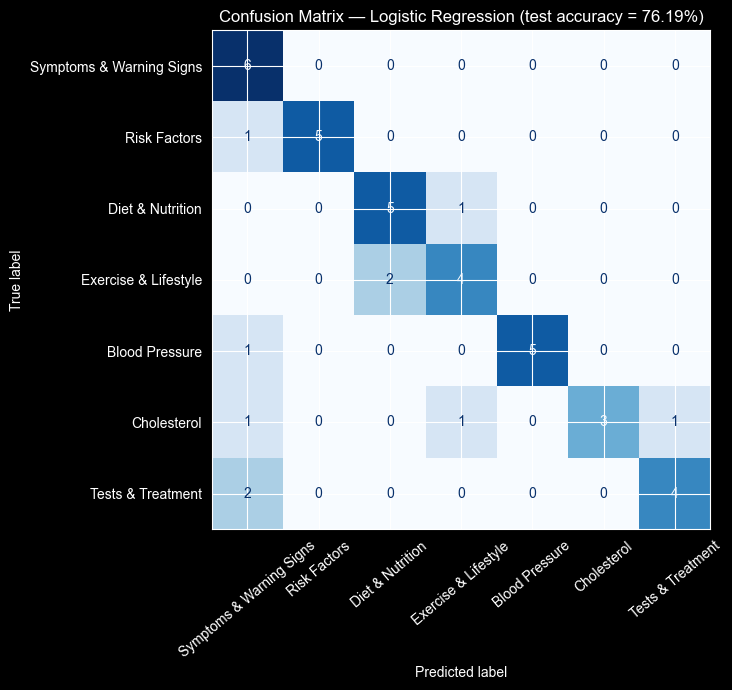

Misclassified test queries:


,query,true,predicted
0,How is heart failure treated?,tests_treatment,symptoms
9,What do the systolic and diastolic numbers mean?,blood_pressure,symptoms
12,What do my lipid profile numbers mean?,cholesterol,symptoms
14,How does good sleep help the heart?,exercise_lifestyle,diet_nutrition
20,How can I manage stress to keep my heart healthy?,exercise_lifestyle,diet_nutrition
21,How is a heart attack diagnosed in hospital?,tests_treatment,symptoms
24,Can exercise raise HDL and lower LDL?,cholesterol,exercise_lifestyle
25,Is coffee safe for people with heart disease?,diet_nutrition,exercise_lifestyle
32,Who is most likely to get heart disease?,risk_factors,symptoms
38,What is atherosclerosis?,cholesterol,tests_treatment


In [19]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
pw, rw, fw, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)

display(pd.DataFrame({"Accuracy": [acc], "Precision (macro)": [p], "Recall (macro)": [r], "F1 (macro)": [f],
                      "Precision (weighted)": [pw], "Recall (weighted)": [rw], "F1 (weighted)": [fw]}).round(3))
print(classification_report(y_test, y_pred, zero_division=0))

labels = list(CORPUS.keys())
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=[INTENT_LABELS[l] for l in labels]).plot(
    ax=ax, cmap="Blues", xticks_rotation=40, colorbar=False)
ax.set_title(f"Confusion Matrix — Logistic Regression (test accuracy = {acc:.2%})")
plt.tight_layout(); plt.show()

errors = pd.DataFrame({"query": q_test, "true": y_test, "predicted": y_pred})
errors = errors[errors.true != errors.predicted]
print("Misclassified test queries:" if len(errors) else "No misclassified test queries.")
if len(errors): display(errors)

**Deployment step.** After evaluation, the final model is **re-fit on all 168 queries** — with a corpus this small, every labelled example improves coverage of real user phrasing. The test-split numbers above remain the honest estimate of generalisation.

In [20]:
model.fit(X_all, y_all)
print("Deployed model trained on", len(X_all), "queries.")

Deployed model trained on 168 queries.


## 7. Domain Knowledge Base
Each intent holds several topic entries (`title`, `keywords`, `answer`). Retrieval is two-stage: the classifier picks the **intent**, then **TF-IDF cosine similarity** picks the best-matching **entry inside that intent** (falling back to the intent's overview entry if nothing overlaps).

Content follows widely published guidance (WHO, ACC/AHA, ICMR). Figures are general reference values, not personal targets.

In [21]:
KB = {
"symptoms": [
    {"title": "Heart attack warning signs",
     "keywords": "heart attack symptom sign warning early chest pain pressure squeeze arm jaw sweat",
     "answer": "Classic heart attack signs: chest pain, pressure, squeezing or heaviness lasting more than a few minutes "
               "(or going and coming back); pain spreading to the left/both arms, jaw, neck, back or upper stomach; "
               "shortness of breath; cold sweat; nausea; light-headedness. Symptoms often build over minutes, "
               "not seconds. If they are happening now, call 112 / 108 immediately."},
    {"title": "Atypical and silent heart attacks",
     "keywords": "women silent without chest pain atypical diabetic elderly fatigue different men",
     "answer": "Women, older adults and people with diabetes more often have atypical symptoms: unusual fatigue, "
               "breathlessness, nausea, indigestion-like discomfort, or back/jaw pain — sometimes with little or no "
               "chest pain. A 'silent' heart attack causes damage that is found later on an ECG or echo. "
               "Unexplained breathlessness or fatigue on exertion deserves a check-up."},
    {"title": "Angina",
     "keywords": "angina feel chest discomfort exertion rest stable unstable",
     "answer": "Angina is chest discomfort caused by reduced blood flow to the heart muscle. Stable angina comes on "
               "with exertion or stress and settles within minutes of rest. Angina that is new, more frequent, "
               "occurs at rest or lasts longer (unstable angina) is a warning of an impending heart attack and "
               "needs urgent medical care."},
    {"title": "Heart failure signs",
     "keywords": "heart failure shortness breath breathless swell ankle leg lie flat weight gain tired",
     "answer": "Heart failure signs include breathlessness on exertion or when lying flat, waking up breathless at "
               "night, swelling of the ankles, feet or legs, rapid weight gain from fluid, persistent fatigue and "
               "a reduced ability to exercise. Swollen ankles have many causes, but with breathlessness they "
               "should be evaluated by a doctor."},
    {"title": "Irregular heartbeat (arrhythmia)",
     "keywords": "irregular heartbeat palpitation flutter racing skip dizzy faint arrhythmia",
     "answer": "Arrhythmia symptoms: palpitations (fluttering, racing, pounding or skipped beats), dizziness, "
               "breathlessness, chest discomfort or fainting. Occasional skipped beats are common and often "
               "harmless; frequent palpitations, or palpitations with fainting or chest pain, need an ECG / Holter "
               "evaluation."},
],
"risk_factors": [
    {"title": "Major risk factors",
     "keywords": "main risk factor cause heart disease habit modifiable non-modifiable",
     "answer": "Modifiable risk factors: high blood pressure, high LDL cholesterol, smoking/tobacco, diabetes, "
               "obesity (especially belly fat), physical inactivity, unhealthy diet, excess alcohol and chronic "
               "stress. Non-modifiable: age, male sex, family history of early heart disease and ethnicity — "
               "South Asians tend to develop heart disease earlier and at lower body weights. Most heart attacks "
               "are linked to the modifiable factors."},
    {"title": "Smoking and tobacco",
     "keywords": "smoking smoke tobacco increase risk heart attack",
     "answer": "Smoking and chewing tobacco damage the artery lining, raise blood pressure and heart rate, and make "
               "blood more likely to clot. There is no safe level. Risk begins to fall soon after quitting and "
               "excess coronary risk drops by about half within a year. National Tobacco Quit Line (India): "
               "1800-11-2356."},
    {"title": "Diabetes",
     "keywords": "diabetes damage heart sugar",
     "answer": "Adults with diabetes are about 2–4 times more likely to develop or die of heart disease. High glucose "
               "damages blood vessels over time and diabetes often travels with high BP and abnormal lipids. "
               "Control sugar (HbA1c targets set by your doctor), BP and cholesterol together."},
    {"title": "Weight and body fat",
     "keywords": "overweight obesity weight affect waist",
     "answer": "Excess weight — particularly abdominal fat — raises BP, LDL, triglycerides and diabetes risk. "
               "For Asian Indians, a waist above 90 cm (men) or 80 cm (women) signals higher risk even at a "
               "normal BMI. Losing even 5–10 % of body weight measurably improves BP and lipids."},
    {"title": "Family history, age and sex",
     "keywords": "hereditary family genetic run age men women sex old",
     "answer": "Risk rises with age (men ≥ 45, women ≥ 55 years) and is higher with a family history of early heart "
               "disease (father/brother before 55, mother/sister before 65). Men are affected earlier; women's "
               "risk climbs after menopause. You can't change these, which makes controlling the modifiable "
               "factors more important."},
    {"title": "Stress, sleep, alcohol and pollution",
     "keywords": "stress sleep alcohol drink pollution air lack",
     "answer": "Chronic stress, regularly sleeping under ~6 hours, heavy alcohol use and long-term exposure to "
               "polluted air all raise BP and cardiovascular risk. Alcohol is not recommended for heart "
               "protection; if you drink, keep it minimal."},
],
"diet_nutrition": [
    {"title": "Heart-healthy foods",
     "keywords": "food good healthy eat breakfast fruit vegetable whole grain fibre nut seed fish",
     "answer": "Build meals around vegetables, fruits, whole grains (oats, millets like ragi/jowar/bajra, brown "
               "rice, whole-wheat roti), legumes (dal, rajma, chana), nuts and seeds, fish and low-fat dairy. "
               "A good breakfast: oats or vegetable poha/upma with curd and fruit, or besan chilla with sprouts."},
    {"title": "Foods to limit",
     "keywords": "avoid bad harmful sugar fried processed junk trans fat",
     "answer": "Limit trans fats (vanaspati, repeatedly reheated frying oil, many bakery and fried snacks), "
               "processed and red meats, sugary drinks and sweets, and salty foods (pickles, papad, namkeen, "
               "instant noodles). WHO advises keeping added sugar below 10 % of daily calories, ideally below 5 %."},
    {"title": "Salt",
     "keywords": "salt sodium much per day",
     "answer": "WHO recommends less than 5 g of salt per day (about one level teaspoon) — including the salt already "
               "in packaged foods, pickles and restaurant meals. Cutting salt is one of the fastest ways to lower "
               "blood pressure."},
    {"title": "Oils, ghee and butter",
     "keywords": "oil cooking ghee butter fat best omega",
     "answer": "Prefer unsaturated oils (mustard, groundnut, rice-bran, olive, sunflower) and rotate them; use all "
               "oils sparingly. Ghee and butter are saturated fats — small amounts are acceptable, but keep "
               "saturated fat under ~10 % of calories. Omega-3s from fish, flaxseed and walnuts support heart health."},
    {"title": "Eggs, coffee and specific foods",
     "keywords": "egg coffee caffeine tea mediterranean diet safe",
     "answer": "For most healthy people, about one egg a day is fine within a balanced diet. Moderate coffee or tea "
               "(without heavy sugar or cream) is safe for most people; those with arrhythmias should ask their "
               "doctor. Mediterranean-style eating — vegetables, legumes, whole grains, nuts, olive oil, fish — "
               "has strong evidence for reducing heart events."},
],
"exercise_lifestyle": [
    {"title": "How much exercise",
     "keywords": "exercise much need best walk walking daily minute week aerobic",
     "answer": "WHO recommends at least 150–300 minutes a week of moderate activity (e.g. brisk walking, cycling, "
               "swimming) or 75–150 minutes of vigorous activity, plus muscle-strengthening on 2 or more days. "
               "A practical target: a 30-minute brisk walk on 5 days a week. Any activity is better than none."},
    {"title": "Strength training and yoga",
     "keywords": "lift weight strength yoga improve",
     "answer": "Moderate resistance training (light-to-moderate weights, controlled breathing, no breath-holding) "
               "is beneficial for most people, including many heart patients once cleared by their doctor. Yoga "
               "and pranayama help lower BP and stress, and improve flexibility."},
    {"title": "Exercise after a heart attack — cardiac rehab",
     "keywords": "after heart attack rehabilitation rehab start safely",
     "answer": "Cardiac rehabilitation is a supervised programme of graded exercise, education and risk-factor "
               "control after a heart attack, angioplasty or bypass. It lowers the chance of another event. Start "
               "only after your cardiologist clears you, begin with short easy walks, and stop if you get chest "
               "pain, severe breathlessness or dizziness."},
    {"title": "Quitting smoking",
     "keywords": "quit smoking stop tobacco",
     "answer": "Set a quit date, remove cigarettes/tobacco from home, identify triggers, and ask a doctor about "
               "nicotine replacement or medication — combining support and medication doubles success rates. "
               "National Tobacco Quit Line (India): 1800-11-2356."},
    {"title": "Sleep, sitting and stress",
     "keywords": "sleep sit sitting long hour stress manage lifestyle change prevent",
     "answer": "Aim for 7–9 hours of sleep; get loud snoring with daytime sleepiness checked (sleep apnoea strains "
               "the heart). Break up long sitting every 30–60 minutes. Manage stress with regular activity, "
               "breathing exercises, meditation and time with people you trust. Together with diet, activity and "
               "no tobacco, these changes prevent most heart disease."},
],
"blood_pressure": [
    {"title": "Normal and high BP ranges",
     "keywords": "normal reading level high considered systolic diastolic number mean monitor",
     "answer": "Systolic (top number) is pressure when the heart beats; diastolic (bottom) is pressure between beats. "
               "ACC/AHA categories (mmHg): Normal < 120/80; Elevated 120–129/<80; Stage 1 hypertension 130–139 or "
               "80–89; Stage 2 ≥ 140 or ≥ 90; Crisis > 180 and/or > 120. Indian guidelines commonly diagnose "
               "hypertension at ≥ 140/90."},
    {"title": "Causes and silent nature",
     "keywords": "cause symptom silent killer young people salt raise hypertension",
     "answer": "Most hypertension has no single cause — it builds from excess salt, excess weight, inactivity, "
               "alcohol, stress, smoking, genetics and age; kidney or hormonal problems cause some cases, "
               "especially in young people. It usually has no symptoms, which is why it's called a 'silent killer' "
               "— the only way to know is to measure it."},
    {"title": "Lowering BP",
     "keywords": "lower reduce naturally control bring without medication decrease cut",
     "answer": "Proven measures: cut salt below 5 g/day, follow a DASH-style diet rich in vegetables, fruit and "
               "low-fat dairy, lose excess weight (≈1 mmHg drop per kg lost), exercise 150 min/week, limit alcohol, "
               "quit tobacco and manage stress. If you've been prescribed BP medication, keep taking it — "
               "lifestyle changes add to medication, they don't replace it without your doctor's advice."},
    {"title": "Low blood pressure",
     "keywords": "low dangerous hypotension dizzy faint",
     "answer": "Low BP (roughly below 90/60) is usually harmless if you feel well. It matters when it causes "
               "dizziness, fainting, blurred vision or confusion, or appears suddenly — causes include dehydration, "
               "bleeding, infection, heart problems or medication. Stand up slowly and see a doctor if symptomatic."},
    {"title": "Home monitoring and complications",
     "keywords": "check home often stroke heart attack complication measure",
     "answer": "Measure after 5 minutes of seated rest, back supported, arm at heart level, no caffeine, smoking or "
               "exercise for 30 minutes; take two readings a minute apart and log them. Adults should check at "
               "least yearly (more often if high). Uncontrolled hypertension is a leading cause of stroke, heart "
               "attack, heart failure and kidney disease."},
],
"cholesterol": [
    {"title": "Cholesterol levels",
     "keywords": "normal level number lipid profile mean triglyceride",
     "answer": "Typical adult reference values (mg/dL): Total cholesterol < 200; LDL < 100 (your doctor may set a "
               "lower target such as < 70 if you're high-risk); HDL > 40 (men) / > 50 (women); Triglycerides < 150."},
    {"title": "LDL vs HDL",
     "keywords": "difference ldl hdl good bad",
     "answer": "LDL ('bad') cholesterol deposits in artery walls and builds plaque. HDL ('good') cholesterol helps carry "
               "cholesterol back to the liver for removal. Lower LDL and adequate HDL mean lower heart risk; "
               "triglycerides are a separate blood fat that rises with sugar, refined carbs and alcohol."},
    {"title": "Lowering LDL / raising HDL",
     "keywords": "reduce lower bring raise ldl hdl food cut decrease",
     "answer": "Replace saturated and trans fats with unsaturated fats; add soluble fibre (oats, isabgol/psyllium, "
               "legumes, fruit); exercise regularly (also raises HDL); lose excess weight; quit smoking (raises HDL); "
               "limit sugar and alcohol (lowers triglycerides). If LDL stays high or your risk is high, doctors "
               "prescribe statins."},
    {"title": "Plaque and atherosclerosis",
     "keywords": "plaque build artery atherosclerosis cause heart disease",
     "answer": "Atherosclerosis is the gradual build-up of plaque (cholesterol, inflammatory cells, calcium) inside "
               "artery walls. Plaque narrows arteries and can rupture, triggering a clot that blocks blood flow — "
               "the usual cause of heart attacks and many strokes. High LDL is a direct driver of this process."},
    {"title": "Testing, genetics and thin people",
     "keywords": "check often test genetic thin familial",
     "answer": "Healthy adults should get a lipid profile at least every 4–6 years from age 20, and more often with "
               "risk factors. Fasting is not always required. Cholesterol is partly genetic — familial "
               "hypercholesterolaemia causes very high LDL from youth — so thin, active people can still have "
               "high cholesterol."},
],
"tests_treatment": [
    {"title": "Diagnostic tests overview",
     "keywords": "test diagnose diagnosis heart disease",
     "answer": "Common tests: ECG (electrical activity), echocardiogram (ultrasound of structure and pumping), "
               "treadmill/stress test, Holter monitor (24–48 h rhythm), troponin blood test (heart-muscle damage), "
               "lipid profile, CT calcium score, and coronary angiography (gold standard for blockages)."},
    {"title": "ECG, echo and stress test",
     "keywords": "ecg electrocardiogram echo echocardiogram treadmill stress test tmt",
     "answer": "An ECG records the heart's electrical signals in minutes — it detects heart attacks, rhythm problems "
               "and strain. An echocardiogram uses ultrasound to show chambers, valves and pumping strength "
               "(ejection fraction). A treadmill stress test (TMT) checks how the heart copes with exertion and "
               "can reveal blockages that a resting ECG misses."},
    {"title": "Angiography, angioplasty, stent and bypass",
     "keywords": "angiography angioplasty stent bypass surgery cabg calcium score coronary",
     "answer": "Coronary angiography injects dye to map blockages. Angioplasty opens a blocked artery with a balloon, "
               "usually leaving a stent (a small mesh tube) to keep it open. Bypass surgery (CABG) routes blood "
               "around blockages using grafted vessels and is preferred for complex multi-vessel disease. A CT "
               "calcium score measures calcified plaque to estimate future risk."},
    {"title": "Common heart medications",
     "keywords": "statin aspirin beta blocker medication side effect prescribe",
     "answer": "Statins lower LDL and stabilise plaque (side effects: muscle aches, rarely liver changes). Aspirin and "
               "other antiplatelets prevent clots in people with known heart disease but raise bleeding risk, so "
               "they are not for everyone. Beta-blockers slow heart rate and lower BP (side effects: tiredness, "
               "cold hands, dizziness). Never start, stop or change a heart medicine without your doctor."},
    {"title": "Pacemaker",
     "keywords": "pacemaker need device slow heartbeat",
     "answer": "A pacemaker is a small device implanted under the skin that sends electrical pulses when the heart "
               "beats too slowly or pauses — e.g. in heart block or sick sinus syndrome. Related devices (ICDs) "
               "can shock dangerous fast rhythms back to normal."},
],
}

assert set(KB) == set(CORPUS), "every intent needs a knowledge-base section"

class KnowledgeBase:
    def __init__(self, kb):
        self.kb = kb
        self.docs, self.index = [], []
        for intent, entries in kb.items():
            for i, e in enumerate(entries):
                # title + keywords weighted 3x over the answer body so retrieval keys on what the entry is *about*
                focus = f"{e['title']} {e['keywords']} "
                self.docs.append(preprocess(focus * 3 + e["answer"]))
                self.index.append((intent, i))
        self.vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(self.docs)
        self.matrix = self.vec.transform(self.docs)

    def retrieve(self, clean_query, intent):
        rows = [k for k, (it, _) in enumerate(self.index) if it == intent]
        if not rows:
            raise KeyError(f"no knowledge-base entries for intent '{intent}'")
        sims = cosine_similarity(self.vec.transform([clean_query]), self.matrix[rows]).ravel()
        best = int(np.argmax(sims)) if sims.max() > 0 else 0   # 0 = overview entry
        _, entry_idx = self.index[rows[best]]
        return self.kb[intent][entry_idx], float(sims[best])

knowledge_base = KnowledgeBase(KB)
display(pd.DataFrame([(INTENT_LABELS[i], len(e), ", ".join(x["title"] for x in e)) for i, e in KB.items()],
                     columns=["intent", "entries", "topics"]))
entry, score = knowledge_base.retrieve(preprocess("how much salt per day"), "diet_nutrition")
print(f"Retrieval demo → '{entry['title']}' (cosine {score:.2f})")

,intent,entries,topics
0,Symptoms & Warning Signs,5,"Heart attack warning signs, Atypical and silent heart attacks, Angina, Heart failure signs, Irregular heartbeat (arr..."
1,Risk Factors,6,"Major risk factors, Smoking and tobacco, Diabetes, Weight and body fat, Family history, age and sex, Stress, sleep, ..."
2,Diet & Nutrition,5,"Heart-healthy foods, Foods to limit, Salt, Oils, ghee and butter, Eggs, coffee and specific foods"
3,Exercise & Lifestyle,5,"How much exercise, Strength training and yoga, Exercise after a heart attack — cardiac rehab, Quitting smoking, Slee..."
4,Blood Pressure,5,"Normal and high BP ranges, Causes and silent nature, Lowering BP, Low blood pressure, Home monitoring and complications"
5,Cholesterol,5,"Cholesterol levels, LDL vs HDL, Lowering LDL / raising HDL, Plaque and atherosclerosis, Testing, genetics and thin p..."
6,Tests & Treatment,5,"Diagnostic tests overview, ECG, echo and stress test, Angiography, angioplasty, stent and bypass, Common heart medic..."


Retrieval demo → 'Salt' (cosine 0.52)


## 8. Reasoning Rules
Eight rules, evaluated in a fixed priority order so safety rules always fire first.

| ID | Rule | Condition | Action |
|---|---|---|---|
| R1 | Input validation | Empty, symbol-only or meaningless input | Ask for a proper question |
| R2 | **Emergency escalation** | A critical phrase (collapsed, not breathing, can't breathe…) **or** a cardiac symptom + an acute marker (now, sudden, severe, crushing, spreading, sweating…) | Stop pipeline → emergency instructions, 112 / 108, CPR guidance |
| R3 | BP-reading reasoning | Query contains a reading like `150/95` | Classify the reading (ACC/AHA); ≥ 180/≥ 120 → crisis protocol |
| R4 | Small talk | Greeting / thanks / goodbye | Friendly reply + capability list |
| R5 | **Unsupported query** | Non-cardiac health term with no heart-domain anchor, or zero overlap with the domain vocabulary | Decline politely, list supported topics, refer to the right doctor |
| R6 | **Low confidence** | Classifier top probability < threshold (or nothing left after preprocessing) | Don't guess — show top-2 likely topics, ask to rephrase |
| R7 | Medication safety | Asks about dose, stopping, skipping or switching medicine | Refuse to give personal dosing advice, give general info, refer to doctor |
| R8 | Symptom safety note | Intent = symptoms | Append "if this is happening now, call 112 / 108" |

**R2 design choice:** a symptom term *alone* does not escalate ("Can left-arm pain be a heart sign?" is informational). It needs either a critical phrase or an acute/first-person-present marker — this avoids crying wolf on every educational query while erring on the side of safety whenever the user describes something happening now.

In [22]:
EMERGENCY_NUMBERS = "📞 Call 112 (national emergency) or 108 (ambulance) NOW."

CRITICAL_PHRASES = [
    "having a heart attack", "heart attack right now", "unconscious", "not breathing", "stopped breathing",
    "collapsed", "passed out", "fainted", "cardiac arrest", "no pulse", "face drooping", "face is drooping",
    "slurred speech", "call an ambulance", "call ambulance", "can't breathe", "cant breathe", "cannot breathe",
    "turning blue", "lips are blue",
]
SYMPTOM_TERMS = [
    "chest pain", "chest pressure", "chest tightness", "tight chest", "pain in my chest", "pain in chest",
    "chest is hurting", "chest hurts", "left arm", "arm is numb", "jaw pain", "breathless", "shortness of breath",
    "palpitation", "heart racing", "heart is racing", "heart is pounding", "dizzy", "dizziness", "sweating",
]
ACUTE_MARKERS = [
    "right now", "now", "suddenly", "sudden", "severe", "crushing", "spreading", "unbearable", "worst",
    "won't go away", "not going away", "for the last", "since morning", "help me", "emergency", "sweating",
    "i am having", "i'm having", "he is having", "she is having",
]

def _has(text, phrases):
    return [p for p in phrases if re.search(rf"(?<![a-z]){re.escape(p)}(?![a-z])", text)]

def rule_input_validation(raw):
    stripped = raw.strip() if isinstance(raw, str) else ""
    if not stripped or not re.search(r"[a-zA-Z]{2,}", stripped):
        return {"type": "invalid_input", "rule": "R1",
                "text": "Please type a heart-health question, e.g. “What foods are good for my heart?”"}
    return None

def rule_emergency(text):
    critical = _has(text, CRITICAL_PHRASES)
    symptoms = _has(text, SYMPTOM_TERMS)
    acute = _has(text, ACUTE_MARKERS)
    if critical or (symptoms and acute):
        trigger = critical or symptoms + acute
        return {"type": "emergency", "rule": "R2", "triggers": trigger,
                "text": ("🚨 THIS MAY BE A MEDICAL EMERGENCY.\n" + EMERGENCY_NUMBERS + "\n"
                         "• Stop all activity; sit or lie in the most comfortable position and loosen tight clothing.\n"
                         "• Do not drive yourself to hospital — wait for the ambulance or get someone to take you.\n"
                         "• If not allergic and no doctor has told you to avoid it, chew one regular-strength "
                         "aspirin (300–325 mg) while waiting.\n"
                         "• If the person is unresponsive and not breathing normally: start hands-only CPR — push "
                         "hard and fast in the centre of the chest, 100–120 compressions per minute, until help arrives.\n"
                         "• Stroke signs (BE-FAST: balance, eyes, face drooping, arm weakness, speech, time) also mean "
                         "call 112 immediately.\n"
                         "I am an information assistant and cannot assess emergencies — please get help now.")}
    return None

BP_PATTERN = re.compile(r"\b(\d{2,3})\s*(?:/|over)\s*(\d{2,3})\b")
CRISIS_SYMPTOMS = ["chest pain", "breath", "headache", "vision", "blurred", "numb", "weakness", "confus", "speech"]

def classify_bp(sys_, dia):
    if sys_ > 180 or dia > 120:   return "Hypertensive crisis range (> 180 and/or > 120)"
    if sys_ >= 140 or dia >= 90:  return "Stage 2 hypertension range (≥ 140 or ≥ 90)"
    if sys_ >= 130 or dia >= 80:  return "Stage 1 hypertension range (130–139 or 80–89)"
    if sys_ >= 120:               return "Elevated (120–129 and < 80)"
    if sys_ < 90 or dia < 60:     return "Low blood pressure range (< 90/60)"
    return "Normal (< 120/80)"

def rule_bp_reading(text):
    m = BP_PATTERN.search(text)
    if not m:
        return None
    sys_, dia = int(m.group(1)), int(m.group(2))
    if not (60 <= sys_ <= 300 and 30 <= dia <= 200 and sys_ > dia):
        return None
    category = classify_bp(sys_, dia)
    if sys_ > 180 or dia > 120:
        if any(s in text for s in CRISIS_SYMPTOMS):
            return {"type": "emergency", "rule": "R3", "bp": (sys_, dia),
                    "text": (f"🚨 A reading of {sys_}/{dia} mmHg with these symptoms may be a hypertensive "
                             f"emergency.\n{EMERGENCY_NUMBERS}\nDo not wait to see if it comes down.")}
        return {"type": "urgent", "rule": "R3", "bp": (sys_, dia),
                "text": (f"⚠️ {sys_}/{dia} mmHg is in the {category}.\n"
                         "• Sit quietly for 5 minutes and measure again.\n"
                         "• If it is still above 180/120, contact your doctor immediately or go to the nearest "
                         "emergency department.\n"
                         "• If you develop chest pain, breathlessness, severe headache, vision change, weakness or "
                         f"confusion: {EMERGENCY_NUMBERS}")}
    # non-crisis readings are annotated, then the normal pipeline answers the question
    return {"type": "note", "rule": "R3", "bp": (sys_, dia),
            "text": f"📊 Your reading {sys_}/{dia} mmHg falls in: {category}. One reading isn't a diagnosis — "
                    "confirm with repeated home readings and your doctor."}

GREETING = re.compile(r"^\s*(hi+|hello|hey|namaste|good (morning|afternoon|evening)|hii+)\b[\s!.,]*$", re.I)
THANKS = re.compile(r"^\s*(thanks?|thank you|thx|ok(ay)? thanks?|great,? thanks?)\b[\s!.,]*$", re.I)
BYE = re.compile(r"^\s*(bye|goodbye|see you|exit|quit)\b[\s!.,]*$", re.I)
CAPABILITIES = ("I can answer questions on: heart attack symptoms & warning signs · risk factors · heart-healthy "
                "diet · exercise & lifestyle · blood pressure · cholesterol · heart tests & treatments.")

def rule_small_talk(raw):
    if GREETING.match(raw): return {"type": "small_talk", "rule": "R4", "text": "Hello! 👋 " + CAPABILITIES}
    if THANKS.match(raw):   return {"type": "small_talk", "rule": "R4", "text": "You're welcome — take care of your heart! ❤️"}
    if BYE.match(raw):      return {"type": "small_talk", "rule": "R4", "text": "Goodbye! Stay heart-healthy. ❤️"}
    return None

HEART_ANCHORS = [
    "heart", "cardiac", "cardio", "chest", "blood pressure", "bp", "hypertension", "cholesterol", "ldl", "hdl",
    "triglyceride", "artery", "arteries", "coronary", "stroke", "ecg", "ekg", "echo", "angina", "angiography",
    "angioplasty", "stent", "bypass", "pacemaker", "pulse", "heartbeat", "palpitation", "statin", "aspirin",
    "beta blocker", "lipid", "plaque", "atherosclerosis", "ticker",
]
OFF_DOMAIN_TERMS = [
    "skin", "acne", "pimple", "rash", "eczema", "hair", "dandruff", "tooth", "teeth", "dental", "gum", "eye",
    "ear", "pregnan", "period", "menstru", "pcos", "cancer", "tumou?r", "covid", "fever", "cold", "cough", "flu",
    "migraine", "kidney stone", "asthma", "knee", "joint", "arthritis", "bone", "fracture", "thyroid", "liver",
    "stomach", "acidity", "gastric", "constipation", "diarrh", "depression", "allerg", "insomnia", "vaccin",
    "typhoid", "dengue", "malaria", "tb", "tuberculosis", "uti", "urine", "piles",
]

def rule_unsupported(text, clean):
    anchors = _has(text, HEART_ANCHORS)
    off = [t for t in OFF_DOMAIN_TERMS if re.search(rf"\b{t}", text)]
    vocab = word_vocab(model)
    overlap = [w for w in clean.split() if w in vocab]
    if (off and not anchors) or (clean and not overlap and not anchors):
        topic = f" ({', '.join(off)})" if off else ""
        return {"type": "unsupported", "rule": "R5", "triggers": off,
                "text": (f"🙏 Sorry, that looks outside my heart-health scope{topic}. " + CAPABILITIES +
                         " For this concern, please consult a general physician or the relevant specialist.")}
    return None

LOW_CONF_THRESHOLD = 0.45   # tuned in §8a

def rule_low_confidence(proba_sorted, clean):
    top_intent, top_p = proba_sorted[0]
    if not clean or top_p < LOW_CONF_THRESHOLD:
        options = " or ".join(f"“{INTENT_LABELS[i]}” ({p:.0%})" for i, p in proba_sorted[:2])
        return {"type": "low_confidence", "rule": "R6",
                "text": (f"🤔 I'm not confident I understood that (best guess {top_p:.0%}). Did you mean {options}?\n"
                         "Please rephrase with specifics — e.g. “What is a normal cholesterol level?” or "
                         "“Which foods lower blood pressure?”")}
    return None

MED_PATTERN = re.compile(r"\b(dose|dosage|mg|how many|stop taking|stop my|skip|missed|double|increase my|"
                         r"decrease my|switch|replace my|instead of my|without my|quit my|reduce my)\b")
MED_TERMS = re.compile(r"\b(medication|statin|aspirin|blocker|tablet|pill|medicine|drug|ecosprin|atorvastatin|"
                       r"rosuvastatin|metoprolol|amlodipine|telmisartan|clopidogrel)s?\b")

def rule_medication_safety(text):
    if MED_PATTERN.search(text) and MED_TERMS.search(normalise(text)):
        return {"type": "note", "rule": "R7",
                "text": ("💊 I can't advise on starting, stopping, skipping or changing the dose of any medicine — "
                         "stopping heart medicines like statins, aspirin/antiplatelets or beta-blockers suddenly can be "
                         "dangerous (stopping antiplatelets after a stent can cause a clot). Please speak to your "
                         "doctor or pharmacist first. General information:")}
    return None

SYMPTOM_NOTE = ("⚠️ If you are experiencing these symptoms right now — especially chest pain lasting more than a few "
                "minutes — " + EMERGENCY_NUMBERS)
DISCLAIMER = "ℹ️ General health information only — not a diagnosis. Please consult a doctor or cardiologist for personal advice."

rules_table = pd.DataFrame([
    ("R1", "Input validation", "pre-NLP"), ("R2", "Emergency escalation", "pre-NLP (highest priority)"),
    ("R3", "BP-reading reasoning", "pre-NLP"), ("R4", "Small talk", "pre-NLP"),
    ("R5", "Unsupported-query handling", "pre-classification"), ("R6", "Low-confidence handling", "post-classification"),
    ("R7", "Medication safety", "post-classification"), ("R8", "Symptom safety note", "response generation"),
], columns=["id", "rule", "stage"])
display(rules_table)

,id,rule,stage
0,R1,Input validation,pre-NLP
1,R2,Emergency escalation,pre-NLP (highest priority)
2,R3,BP-reading reasoning,pre-NLP
3,R4,Small talk,pre-NLP
4,R5,Unsupported-query handling,pre-classification
5,R6,Low-confidence handling,post-classification
6,R7,Medication safety,post-classification
7,R8,Symptom safety note,response generation


### 8a. Tuning the low-confidence threshold
In-domain queries the model handles correctly should clear the threshold; vague queries should fall below it. We inspect the confidence distribution of **correct vs. incorrect held-out predictions** (from a model trained only on the training split) and of deliberately vague queries, then sweep candidate thresholds.

The chosen **0.45** sits just above the vague-query band: it deflects most wrong predictions at the cost of re-asking on a minority of borderline-but-correct ones — the right trade-off for a health assistant, where a confident wrong answer is worse than a clarifying question.

Held-out CORRECT predictions   : min 0.36 | mean 0.73
Held-out INCORRECT predictions : max 0.52 | mean 0.37


,vague query,top confidence
0,Is my heart okay?,0.41
1,Tell me something about the heart,0.36
2,What should I know about health?,0.38
3,Heart stuff,0.42
4,I want to ask something,0.25


,threshold,answered,accuracy when answered,wrong answers deflected
0,0.30,93%,82%,3 / 10
1,0.35,90%,84%,4 / 10
2,0.40,83%,89%,6 / 10
3,0.45,74%,94%,8 / 10
4,0.50,74%,94%,8 / 10


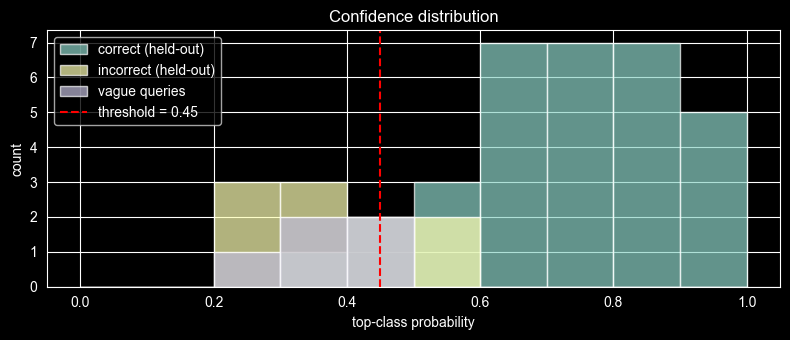

In [23]:
probe = make_model().fit(X_train, y_train)
test_proba = probe.predict_proba(X_test).max(axis=1)
test_correct = probe.predict(X_test) == y_test

vague = ["Is my heart okay?", "Tell me something about the heart", "What should I know about health?",
         "Heart stuff", "I want to ask something"]
vague_conf = model.predict_proba([preprocess(v) for v in vague]).max(axis=1)

print(f"Held-out CORRECT predictions   : min {test_proba[test_correct].min():.2f} | "
      f"mean {test_proba[test_correct].mean():.2f}")
if (~test_correct).any():
    print(f"Held-out INCORRECT predictions : max {test_proba[~test_correct].max():.2f} | "
          f"mean {test_proba[~test_correct].mean():.2f}")
display(pd.DataFrame({"vague query": vague, "top confidence": vague_conf.round(2)}))

sweep = []
for t in (0.30, 0.35, 0.40, 0.45, 0.50):
    keep = test_proba >= t
    sweep.append({"threshold": t, "answered": f"{keep.mean():.0%}",
                  "accuracy when answered": f"{test_correct[keep].mean():.0%}" if keep.any() else "—",
                  "wrong answers deflected": f"{(~keep & ~test_correct).sum()} / {(~test_correct).sum()}"})
display(pd.DataFrame(sweep))

plt.figure(figsize=(8, 3.5))
plt.hist(test_proba[test_correct], bins=10, range=(0, 1), alpha=0.7, label="correct (held-out)")
if (~test_correct).any():
    plt.hist(test_proba[~test_correct], bins=10, range=(0, 1), alpha=0.7, label="incorrect (held-out)")
plt.hist(vague_conf, bins=10, range=(0, 1), alpha=0.7, label="vague queries")
plt.axvline(LOW_CONF_THRESHOLD, color="red", ls="--", label=f"threshold = {LOW_CONF_THRESHOLD}")
plt.xlabel("top-class probability"); plt.ylabel("count"); plt.legend(); plt.title("Confidence distribution")
plt.tight_layout(); plt.show()

## 9. Integrated Cognitive Assistant
`HeartHealthAssistant.respond()` runs the full chain — rules → NLP → TF-IDF → classifier → rules → knowledge-base retrieval → knowledge-graph reasoning → response — and returns a structured result (type, intent, confidence, rules fired, retrieved topic, text), so every answer is explainable.

In [24]:
class HeartHealthAssistant:
    def __init__(self, model, knowledge_base, threshold=LOW_CONF_THRESHOLD):
        self.model = model
        self.kb = knowledge_base
        self.threshold = threshold
        self.history = []

    def _result(self, query, **kw):
        res = {"query": query, "type": kw.get("type"), "intent": kw.get("intent"),
               "confidence": kw.get("confidence"), "rules_fired": kw.get("rules_fired", []),
               "kb_topic": kw.get("kb_topic"), "concepts": kw.get("concepts", []), "text": kw.get("text", "")}
        self.history.append(res)
        return res

    def respond(self, query):
        raw = query if isinstance(query, str) else ""
        fired = []
        try:
            # ---- R1: input validation
            r = rule_input_validation(raw)
            if r: return self._result(raw, type=r["type"], rules_fired=["R1"], text=r["text"])
            text = normalise(raw)

            # ---- R2: emergency escalation (highest priority)
            r = rule_emergency(text)
            if r: return self._result(raw, type="emergency", rules_fired=["R2"], text=r["text"])

            # ---- R3: BP-reading reasoning
            notes = []
            r = rule_bp_reading(text)
            if r:
                fired.append("R3")
                if r["type"] in ("emergency", "urgent"):
                    return self._result(raw, type=r["type"], intent="blood_pressure", rules_fired=fired, text=r["text"])
                notes.append(r["text"])

            # ---- R4: small talk
            r = rule_small_talk(raw)
            if r: return self._result(raw, type="small_talk", rules_fired=["R4"], text=r["text"])

            # ---- NLP preprocessing
            clean = preprocess(raw)

            # ---- R5: unsupported query
            r = rule_unsupported(text, clean)
            if r: return self._result(raw, type="unsupported", rules_fired=fired + ["R5"], text=r["text"])

            # ---- intent classification
            if clean:
                proba = self.model.predict_proba([clean])[0]
                ranked = sorted(zip(self.model.classes_, proba), key=lambda x: -x[1])
            else:
                ranked = [(c, 0.0) for c in self.model.classes_]
            intent, conf = ranked[0]
            if "R3" in fired and intent != "blood_pressure" and conf < 0.6:
                intent = "blood_pressure"                        # a BP reading anchors the topic

            # ---- R6: low confidence
            r = rule_low_confidence(ranked, clean) if "R3" not in fired else None
            if r:
                return self._result(raw, type="low_confidence", intent=intent, confidence=float(conf),
                                    rules_fired=fired + ["R6"], text=r["text"])

            # ---- R7: medication safety
            r = rule_medication_safety(text)
            if r:
                fired.append("R7")
                notes.append(r["text"])
                intent = "tests_treatment"

            # ---- knowledge retrieval + knowledge-graph reasoning
            entry, sim = self.kb.retrieve(clean, intent)
            concepts = detect_concepts(text)
            facts = kg_facts(concepts)

            parts = notes + [f"🫀 {entry['title']}", entry["answer"]]
            if facts:
                parts.append("🔗 Related facts: " + "; ".join(facts) + ".")
            # ---- R8: symptom safety note
            if intent == "symptoms":
                fired.append("R8")
                parts.append(SYMPTOM_NOTE)
            parts.append(DISCLAIMER)
            header = f"[Intent: {INTENT_LABELS[intent]} | confidence {conf:.0%} | {INTENT_TAXONOMY[intent]}]"
            return self._result(raw, type="answer", intent=intent, confidence=float(conf), rules_fired=fired,
                                kb_topic=entry["title"], concepts=concepts, text=header + "\n" + "\n".join(parts))
        except Exception as exc:   # never crash the chat loop
            return self._result(raw, type="error", rules_fired=fired,
                                text=f"Sorry — something went wrong while processing that ({type(exc).__name__}). "
                                     "Please try rephrasing.")

assistant = HeartHealthAssistant(model, knowledge_base)
print(assistant.respond("Which cooking oil is best for my heart?")["text"])

[Intent: Diet & Nutrition | confidence 76% | Prevention & Lifestyle › Diet & Nutrition]
🫀 Oils, ghee and butter
Prefer unsaturated oils (mustard, groundnut, rice-bran, olive, sunflower) and rotate them; use all oils sparingly. Ghee and butter are saturated fats — small amounts are acceptable, but keep saturated fat under ~10 % of calories. Omega-3s from fish, flaxseed and walnuts support heart health.
🔗 Related facts: Healthy Diet lowers High LDL Cholesterol.
ℹ️ General health information only — not a diagnosis. Please consult a doctor or cardiologist for personal advice.


## 10. Interactive Interface (Google Colab)
Type a question and press **Ask** (or Enter). The chat keeps history, so you can ask any number of queries; **Clear** resets the view. Quick-test buttons fire one of each required test case.

> If widgets don't render in your environment, use the text-loop cell in §10b instead.

In [25]:
import ipywidgets as widgets
from IPython.display import display, HTML
import html as _html

try:  # enable widget rendering in Colab
    from google.colab import output as _colab_output
    _colab_output.enable_custom_widget_manager()
except Exception:
    pass

TYPE_STYLE = {
    "emergency": ("#fdecea", "#c0392b"), "urgent": ("#fff4e5", "#e67e22"), "unsupported": ("#f4f0fa", "#7d3c98"),
    "low_confidence": ("#fffbe6", "#b7950b"), "answer": ("#eef7f1", "#1e8449"), "small_talk": ("#eaf2fb", "#2471a3"),
    "invalid_input": ("#f2f3f4", "#566573"), "error": ("#f2f3f4", "#566573"),
}

def render(res):
    bg, fg = TYPE_STYLE.get(res["type"], ("#f2f3f4", "#566573"))
    meta = f"type: <b>{res['type']}</b>"
    if res["intent"]: meta += f" · intent: <b>{INTENT_LABELS[res['intent']]}</b>"
    if res["confidence"] is not None: meta += f" · confidence: <b>{res['confidence']:.0%}</b>"
    if res["rules_fired"]: meta += f" · rules: <b>{', '.join(res['rules_fired'])}</b>"
    body = _html.escape(res["text"]).replace("\n", "<br>")
    return (f"<div style='margin:6px 0;padding:8px 12px;background:#e8eaf6;border-radius:10px;text-align:right'>"
            f"🧑 <b>{_html.escape(res['query'])}</b></div>"
            f"<div style='margin:6px 0 14px;padding:10px 14px;background:{bg};border-left:5px solid {fg};"
            f"border-radius:8px;color:#1b1b1b;line-height:1.45'><div style='font-size:11px;color:{fg};"
            f"margin-bottom:6px'>{meta}</div>{body}</div>")

query_box = widgets.Text(placeholder="Ask a heart-health question…", layout=widgets.Layout(width="70%"))
ask_btn = widgets.Button(description="Ask", button_style="danger", icon="heart")
clear_btn = widgets.Button(description="Clear", icon="trash")
chat_out = widgets.Output(layout=widgets.Layout(border="1px solid #ddd", padding="8px",
                                                max_height="520px", overflow_y="auto"))

QUICK_TESTS = {
    "Intent: diet": "Which fruits and vegetables are best for my heart?",
    "Reworded": "How can I bring my BP down without tablets?",
    "Unsupported": "What is the best treatment for acne on my face?",
    "Low-confidence": "Is my heart okay?",
    "Emergency": "I have crushing chest pain spreading to my left arm and I am sweating",
}

def ask(q):
    res = assistant.respond(q)
    with chat_out:
        display(HTML(render(res)))

def on_ask(_):
    q = query_box.value
    query_box.value = ""
    ask(q)

def on_clear(_):
    chat_out.clear_output()

ask_btn.on_click(on_ask)
clear_btn.on_click(on_clear)
try:
    query_box.on_submit(on_ask)          # Enter key
except Exception:
    pass

quick_btns = []
for label, q in QUICK_TESTS.items():
    b = widgets.Button(description=label, layout=widgets.Layout(width="auto"))
    b.on_click(lambda _, q=q: ask(q))
    quick_btns.append(b)

display(HTML("<h3 style='margin:4px 0'>🫀 Heart Health Information Assistant</h3>"
             "<div style='color:#666;font-size:12px'>General information only — not medical advice. "
             "In an emergency call 112 / 108.</div>"))
display(widgets.VBox([widgets.HBox([query_box, ask_btn, clear_btn]),
                      widgets.HBox(quick_btns, layout=widgets.Layout(flex_flow="row wrap")), chat_out]))
ask("hello")

### 10b. Text-based chat loop (fallback)
Runs an `input()` loop that accepts multiple queries; type `exit` to stop.

In [26]:
def run_cli():
    print("Heart Health Information Assistant — type 'exit' to quit.\n")
    while True:
        try:
            q = input("You: ")
        except (EOFError, KeyboardInterrupt):
            print("\nSession ended."); break
        if q.strip().lower() in {"exit", "quit", "bye"}:
            print("Assistant: Goodbye! Stay heart-healthy. ❤️"); break
        res = assistant.respond(q)
        tag = res["type"]
        if res["intent"]:
            tag += " · " + INTENT_LABELS[res["intent"]]
        if res["confidence"] is not None:
            tag += f" · {res['confidence']:.0%}"
        print(f"\nAssistant [{tag}]:\n{res['text']}\n")

try:
    run_cli()
except Exception as exc:   # e.g. StdinNotImplementedError when executed headlessly
    print(f"Interactive input unavailable in this environment ({type(exc).__name__}). "
          "Run this cell in Colab to chat, or use the widget above.")

Heart Health Information Assistant — type 'exit' to quit.


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are good for my heart?”


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are good for my heart?”


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are good for my heart?”


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are good for my heart?”


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are good for my heart?”


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are good for my heart?”


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are good for my heart?”


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are good for my heart?”


Assistant [invalid_input]:
Please type a heart-health question, e.g. “What foods are

## 11. Testing the Assistant
All five required test categories, plus extra cases that exercise the remaining rules (R1, R3, R4, R7).

| # | Required test | Expected behaviour |
|---|---|---|
| 1 | One query per defined intent (7) | Correct intent + relevant KB topic |
| 2 | Differently-worded query | Same intent as its corpus counterpart despite new vocabulary |
| 3 | Unsupported healthcare query | R5 fires, polite redirect |
| 4 | Low-confidence query | R6 fires, top-2 suggestions, asks to rephrase |
| 5 | Emergency-related query | R2 fires, 112/108 escalation before any NLP |

In [27]:
TEST_CASES = [
    # (test category, query, expected type, expected intent)
    ("1. Intent — symptoms",           "What symptoms show up before a heart attack?",                        "answer", "symptoms"),
    ("1. Intent — risk factors",       "Does tobacco use raise my chance of getting heart disease?",          "answer", "risk_factors"),
    ("1. Intent — diet",               "Which fruits and vegetables are best for my heart?",                  "answer", "diet_nutrition"),
    ("1. Intent — exercise",           "How many minutes should I walk every day for heart fitness?",         "answer", "exercise_lifestyle"),
    ("1. Intent — blood pressure",     "What is considered a healthy blood pressure level for adults?",       "answer", "blood_pressure"),
    ("1. Intent — cholesterol",        "How do I bring down bad cholesterol?",                                "answer", "cholesterol"),
    ("1. Intent — tests & treatment",  "Why would a cardiologist ask for an echo test?",                      "answer", "tests_treatment"),
    ("2. Differently worded",          "How can I bring my BP down without tablets?",                         "answer", "blood_pressure"),
    ("2. Differently worded",          "What eatables are good for my ticker?",                               "answer", "diet_nutrition"),
    ("3. Unsupported",                 "What is the best treatment for acne on my face?",                     "unsupported", None),
    ("3. Unsupported",                 "How do I get rid of a migraine headache?",                            "unsupported", None),
    ("4. Low confidence",              "Is my heart okay?",                                                   "low_confidence", None),
    ("4. Low confidence",              "Tell me something about the heart",                                   "low_confidence", None),
    ("5. Emergency",                   "I have crushing chest pain spreading to my left arm and I am sweating", "emergency", None),
    ("5. Emergency",                   "My father just collapsed and is not breathing",                       "emergency", None),
    ("Extra — R3 BP crisis",           "My BP is 190/125, what should I do?",                                 "urgent", "blood_pressure"),
    ("Extra — R3 BP note",             "My reading is 145/92, is that high?",                                 "answer", "blood_pressure"),
    ("Extra — R7 medication",          "Can I stop taking my statin tablets?",                                "answer", "tests_treatment"),
    ("Extra — R4 small talk",          "hello",                                                               "small_talk", None),
    ("Extra — R1 invalid",             "   ???   ",                                                           "invalid_input", None),
]

rows = []
for cat, q, exp_type, exp_intent in TEST_CASES:
    res = assistant.respond(q)
    ok = res["type"] == exp_type and (exp_intent is None or res["intent"] == exp_intent)
    rows.append({"test": cat, "query": q, "response type": res["type"],
                 "intent": INTENT_LABELS.get(res["intent"], "—") if res["intent"] else "—",
                 "confidence": f"{res['confidence']:.0%}" if res["confidence"] is not None else "—",
                 "rules": ", ".join(res["rules_fired"]) or "—", "KB topic": res["kb_topic"] or "—",
                 "pass": "✅" if ok else "❌"})
results = pd.DataFrame(rows)
display(results)
print(f"\nPassed {(results['pass'] == '✅').sum()} / {len(results)} test cases.")

,test,query,response type,intent,confidence,rules,KB topic,pass
0,1. Intent — symptoms,What symptoms show up before a heart attack?,answer,Symptoms & Warning Signs,87%,R8,Heart attack warning signs,✅
1,1. Intent — risk factors,Does tobacco use raise my chance of getting heart disease?,answer,Risk Factors,82%,—,Smoking and tobacco,✅
2,1. Intent — diet,Which fruits and vegetables are best for my heart?,answer,Diet & Nutrition,83%,—,Heart-healthy foods,✅
3,1. Intent — exercise,How many minutes should I walk every day for heart fitness?,answer,Exercise & Lifestyle,91%,—,How much exercise,✅
4,1. Intent — blood pressure,What is considered a healthy blood pressure level for adults?,answer,Blood Pressure,87%,—,Normal and high BP ranges,✅
5,1. Intent — cholesterol,How do I bring down bad cholesterol?,answer,Cholesterol,98%,—,Lowering LDL / raising HDL,✅
6,1. Intent — tests & treatment,Why would a cardiologist ask for an echo test?,answer,Tests & Treatment,87%,—,"ECG, echo and stress test",✅
7,2. Differently worded,How can I bring my BP down without tablets?,answer,Blood Pressure,83%,—,Lowering BP,✅
8,2. Differently worded,What eatables are good for my ticker?,answer,Diet & Nutrition,91%,—,Heart-healthy foods,✅
9,3. Unsupported,What is the best treatment for acne on my face?,unsupported,—,—,R5,—,✅



Passed 20 / 20 test cases.


### Full responses for the five required test categories

In [28]:
SHOWCASE = [
    "Which fruits and vegetables are best for my heart?",
    "How can I bring my BP down without tablets?",
    "What is the best treatment for acne on my face?",
    "Is my heart okay?",
    "I have crushing chest pain spreading to my left arm and I am sweating",
]
for q in SHOWCASE:
    res = assistant.respond(q)
    print("=" * 100)
    print(f"USER      : {q}")
    print(f"TYPE      : {res['type']}   RULES: {', '.join(res['rules_fired']) or '—'}")
    print("-" * 100)
    print(res["text"])
print("=" * 100)

USER      : Which fruits and vegetables are best for my heart?
TYPE      : answer   RULES: —
----------------------------------------------------------------------------------------------------
[Intent: Diet & Nutrition | confidence 83% | Prevention & Lifestyle › Diet & Nutrition]
🫀 Heart-healthy foods
Build meals around vegetables, fruits, whole grains (oats, millets like ragi/jowar/bajra, brown rice, whole-wheat roti), legumes (dal, rajma, chana), nuts and seeds, fish and low-fat dairy. A good breakfast: oats or vegetable poha/upma with curd and fruit, or besan chilla with sprouts.
ℹ️ General health information only — not a diagnosis. Please consult a doctor or cardiologist for personal advice.
USER      : How can I bring my BP down without tablets?
TYPE      : answer   RULES: —
----------------------------------------------------------------------------------------------------
[Intent: Blood Pressure | confidence 83% | Cardiovascular Conditions › Hypertension]
🫀 Lowering BP
Proven m

## 12. Conclusion
- **NLP + ML:** lowercase → synonym normalisation → tokenisation → stopword removal → lemmatisation feeds a word + character TF-IDF Logistic Regression classifier over 7 intents; NB, LR and SVM were compared with repeated 5-fold CV and the chosen model evaluated on a held-out split with accuracy, precision, recall, F1 and a confusion matrix.
- **Knowledge representation:** a 5-category / 14-subcategory taxonomy, a 17-concept / 18-relation knowledge graph used at answer time, and a per-intent knowledge base retrieved by TF-IDF cosine similarity.
- **Reasoning & safety:** 8 prioritised rules — emergency escalation and BP-crisis detection run *before* the classifier, so a life-threatening message is never left to a probabilistic model; low-confidence and unsupported queries are deflected instead of guessed.

**Limitations.** The corpus is small (168 queries), so unseen vocabulary relies on the synonym map; rule keyword lists can miss unusual phrasings of emergencies; the assistant gives general information only and is not a diagnostic tool. Natural extensions: sentence-embedding intent models, a larger crowd-sourced corpus, Hindi/Hinglish support, and RAG over vetted guideline documents.